# Analisi iniziale dei dati

## Evoluzione delle anime negli anni

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import plotly.graph_objects as go
import ast
import plotly.express as px
from matplotlib.pyplot import legend

from solution.utils import *
from solution.utils.details_utils import parse_genres_column, explode_genres


In [2]:
# load dataset
details = pd.read_csv("../dataset/cleaned/details_cleaned.csv")
favs = pd.read_csv("../dataset/cleaned/favs_cleaned.csv")
recommendations = pd.read_csv("../dataset/cleaned/recommendations_cleaned.csv")
stats = pd.read_csv("../dataset/cleaned/stats_cleaned.csv")
#ratings = pd.read_csv("../dataset/cleaned/ratings_cleaned.csv")


In [3]:
details['start_date'] = pd.to_datetime(details['start_date'], errors='coerce')
details['year'] = details['start_date'].dt.year.astype("Int64")
details['scored_by'] = pd.to_numeric(details['scored_by'], errors='coerce')



### Nella prima parte viene presentata un’analisi temporale della produzione, utile a contestualizzare storicamente il fenomeno. Le sezioni successive approfondiscono aspetti legati alla popolarità, ai rating degli utenti e alle fonti di ispirazione

In [4]:
details = details.copy()
details = details.dropna(subset=['start_date'])

# Conteggio anime per anno
counts = (details['year'].value_counts().sort_index().reset_index())
counts.columns = ['year', 'anime_count']

fig = px.line(counts,x='year',y='anime_count',markers=True,
    title="Numero di anime per anno di inizio",
    labels={'year': 'Anno di inizio','anime_count': 'Numero di anime'},
    hover_data={'year': True,'anime_count': True})
fig.update_traces(marker=dict(size=5),line=dict(width=2))
fig.update_layout(
    xaxis=dict(range=[1917, 2024]),
    hovermode="x unified",
    template="plotly_dark",
    title_font_size=14
)
fig.show()

Dagli anni ’70 in poi si osserva una **crescita** quasi **esponenziale** del numero di anime prodotti, con un’accelerazione marcata dopo il 2000.
Negli ultimi anni, invece, il trend mostra oscillazioni e un leggero **calo**, suggerendo una possibile fase di saturazione del mercato.

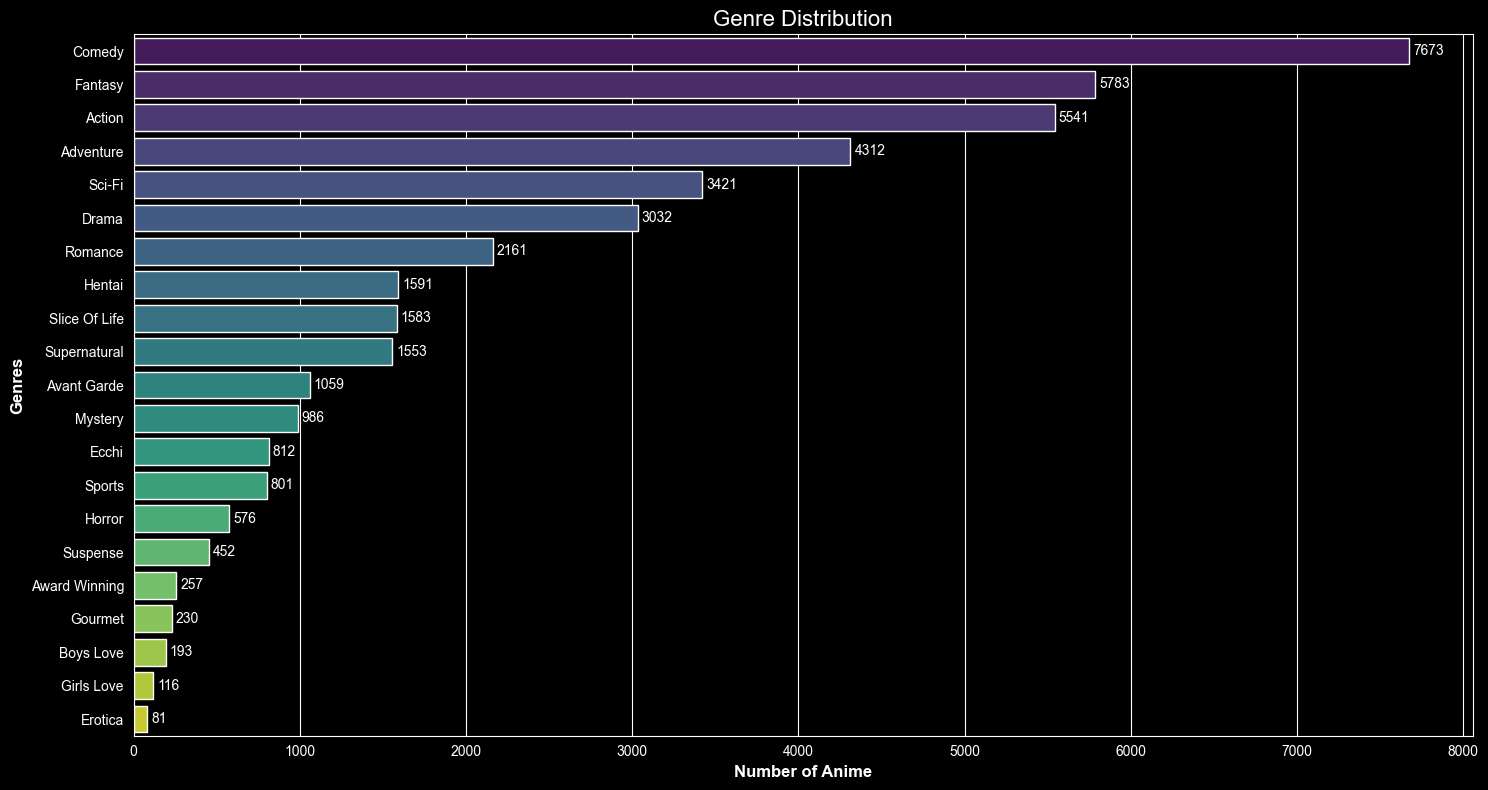

In [5]:
# Convert genres from string to list
details['genres'] = details['genres'].apply(ast.literal_eval)
# Explode genres for plotting
details = details.explode('genres').dropna(subset=['genres'])
# Count genres
genre_count = details['genres'].value_counts().reset_index()
genre_count.columns = ['genre', 'count']
# plot
plt.figure(figsize=(15, 8))
ax = sns.barplot(data=genre_count, x='count', y='genre', hue='genre', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Genre Distribution', fontsize=16)
plt.xlabel('Number of Anime', fontsize=12, fontweight='bold')
plt.ylabel('Genres', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


## Evoluzione dei principali generi anime nel tempo

### Come cambiano i generi anime dal 1917 a oggi

In [6]:
details = details.dropna(subset=['start_date'])
print(details)
# filtro anni VALIDI
details = details[(details['year'] >= 1917) & (details['year'] <= 2024)]
# explode generi
genres_df = details.explode('genres')
# conteggio per anno e genere
genre_year = (genres_df.groupby(['year', 'genres']).size() .reset_index(name='count'))
# grafico
fig = go.Figure()
for genre in sorted(genre_year['genres'].unique()):
    df_g = genre_year[genre_year['genres'] == genre]
    fig.add_trace(
        go.Scatter(
            x=df_g['year'],
            y=df_g['count'],
            mode='lines',
            name=genre,
            visible='legendonly'
        )
    )
fig.update_layout(
    title="Anime production over time by genre",
    xaxis_title="Year",
    yaxis_title="Number of anime released",
    template="plotly_dark",
    hovermode="x unified",
    legend_title="Click genres to show / hide"
)
fig.show()

Questo grafico mostra l’evoluzione dei principali generi anime nel tempo, evidenziando come la crescita dell’industria sia stata accompagnata da una progressiva specializzazione dei contenuti.

Fino agli anni ’80 la produzione è limitata e relativamente omogenea, mentre a partire dagli anni ’90 emergono differenze sempre più marcate tra i generi.

Dopo il 2000 si osserva una forte espansione di generi come **Action**, **Fantasy** e **Comedy**, riflettendo l’ampliamento del pubblico e la diversificazione dei gusti.

Negli anni più recenti alcune curve mostrano una stabilizzazione o una lieve flessione, suggerendo una fase di assestamento del mercato più che una diminuzione di interesse

#### Ok, abbiamo visto come cambiano le cose nel tempo. Ora guardiamo com’è fatto l’ecosistema complessivo.

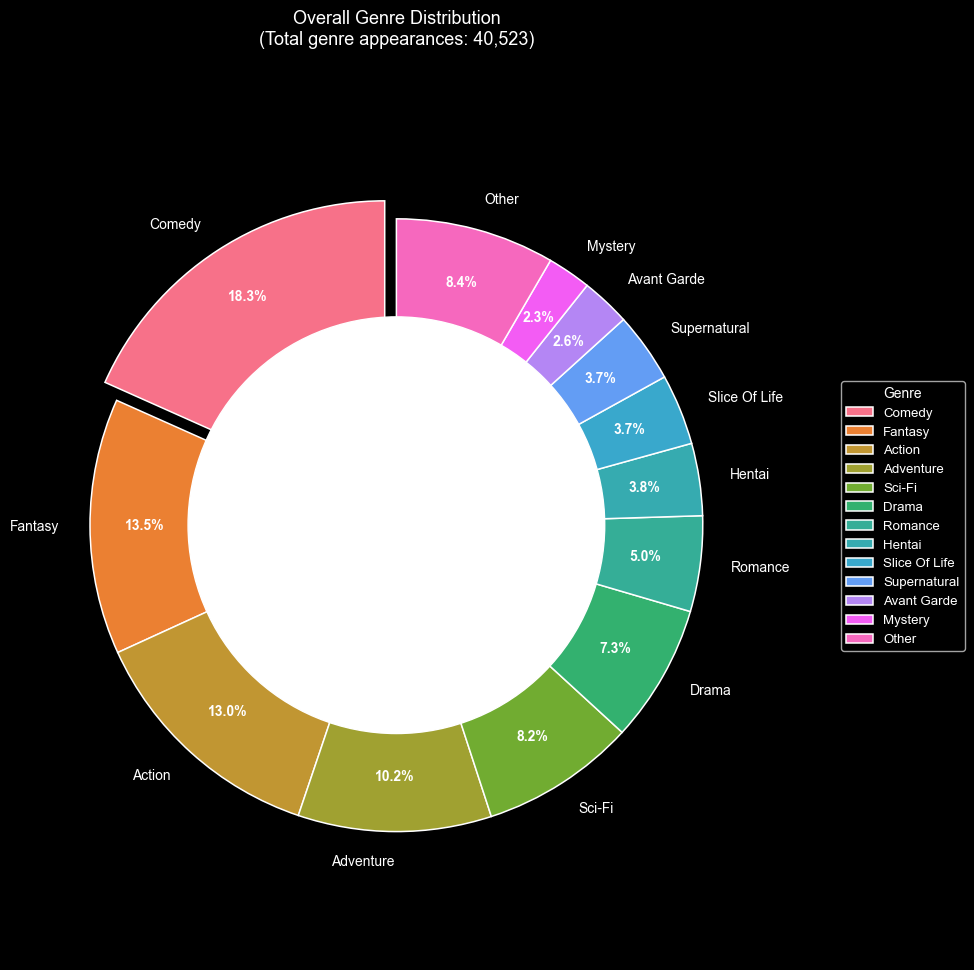

In [7]:
# conta quante volte compare ogni genere
genre_total = genres_df['genres'].value_counts()
# numeri di generi principali da mostrare singolarmente nel pie
top_n_pie = 12
# prendiamo solo i primi N generi più frequentati
top_genres_pie = genre_total.head(top_n_pie)
# sommiamo tutti i generi rimnenti , ciè dal 13 e in poi
other_count = genre_total.iloc[top_n_pie:].sum()
# creiamo la categoria "other"
if other_count > 0:
    pie_data = pd.concat([
        top_genres_pie,
        pd.Series({'Other': other_count})
    ])
else:
    pie_data = top_genres_pie
# creazione grafico
plt.figure(figsize=(10, 10))
colors = sns.color_palette("husl", len(pie_data))
# explode solo sulla fetta più frequente
explode = [0.07 if genre == pie_data.idxmax() else 0 for genre in pie_data.index]
# disegno pie chart
wedges, texts, autotexts = plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    explode=explode,
    pctdistance=0.82,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.1},
    textprops={'fontsize': 10}
)
# stile delle percentuali
for autotext in autotexts:autotext.set_color('white'), autotext.set_fontweight('bold')
# titoli
plt.title(f"Overall Genre Distribution\n(Total genre appearances: {genre_total.sum():,})",fontsize=13, pad=20)
# cerchio centrale per effetto 'donut'
centre_circle = plt.Circle((0, 0), 0.68, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# legenda
plt.legend(pie_data.index,title="Genre",loc="center left",bbox_to_anchor=(1.15, 0.5),fontsize=9.5)

plt.axis('equal')
plt.tight_layout()
plt.show()

I risultati evidenziano una forte predominanza di generi orientati all’intrattenimento di massa, come Comedy, Action e Fantasy, che rappresentano una parte significativa della produzione totale.

Accanto a questi, emerge una varietà di generi meno rappresentati che contribuiscono alla diversificazione dell’offerta, suggerendo un ecosistema ricco e stratificato piuttosto che dominato da una singola tendenza.

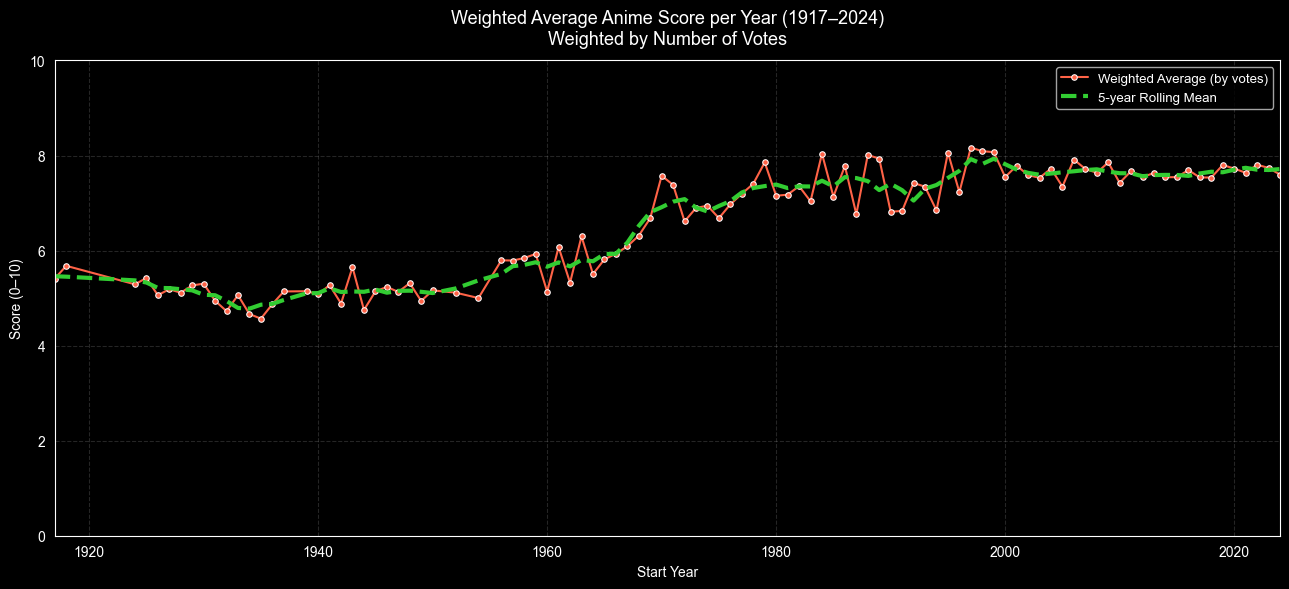

In [8]:
# filtro per il calcolo della media pesata
df_weighted = details[
    details['score'].notna() &
    details['scored_by'].notna() &
    (details['scored_by'] > 0) &
    details['year'].notna()
].copy()

# limitiamo l'analisi agli anni con dati storicamnete rilevanti
df_weighted = df_weighted[df_weighted['year'] >= 1917]

# calcolo di media dei punteggi, totale dei voti, numero di anime rilasciati
year_weighted = df_weighted.groupby('year', group_keys=False).apply(
    lambda x: pd.Series({
        'weighted_mean': (x['score'] * x['scored_by']).sum() / x['scored_by'].sum(),
        'total_votes': x['scored_by'].sum(),
        'anime_count': len(x)
    }),
    include_groups=False
).reset_index()
# Ordina per sicurezza
year_weighted = year_weighted.sort_values('year')
# calcoliamo una media mobile centrata su 5 anni per rendere il trend più leggibile
year_weighted['rolling_weighted'] = year_weighted['weighted_mean'].rolling(window=5, center=True, min_periods=2).mean()
# visualizzazione
plt.figure(figsize=(13, 6))
# Linea principale: media pesata
sns.lineplot(data=year_weighted,x='year',y='weighted_mean',color='tomato',linewidth=1.5,marker='o',markersize=4,label='Weighted Average (by votes)')
# media mobile
plt.plot(
    year_weighted['year'],
    year_weighted['rolling_weighted'],
    color='limegreen',
    linewidth=3,
    linestyle='--',
    label='5-year Rolling Mean'
)
plt.title("Weighted Average Anime Score per Year (1917–2024)\nWeighted by Number of Votes",fontsize=13,pad=12)
plt.xlabel("Start Year")
plt.ylabel("Score (0–10)")
# limiti degli assi per una scala coerente
plt.xlim(year_weighted['year'].min(), year_weighted['year'].max())
plt.ylim(0, 10)

plt.grid(True, alpha=0.15, linestyle='--')
plt.legend(fontsize=9.5)
plt.tight_layout()
plt.show()

Il grafico mostra l’andamento del punteggio medio degli anime dal 1917 al 2024, calcolato come media pesata sul numero di voti, così da dare maggiore importanza ai titoli più rilevanti per il pubblico.

Nei primi decenni la qualità media si mantiene su valori bassi e stabili, riflettendo una fase iniziale e sperimentale dell’industria. A partire dagli anni ’60 si osserva invece una crescita progressiva e significativa, in parallelo allo sviluppo dell’anime moderno e al consolidamento degli studi di animazione.

Dagli anni ’90 in poi, il punteggio medio raggiunge valori elevati e tende a stabilizzarsi, come evidenziato dalla media mobile a 5 anni. Questo suggerisce che, nonostante l’aumento della produzione, la qualità percepita dagli utenti rimane costante nel tempo, indicando una fase di maturità dell’industria anime.


### I generi più prodotti sono anche quelli più amati dai fan?

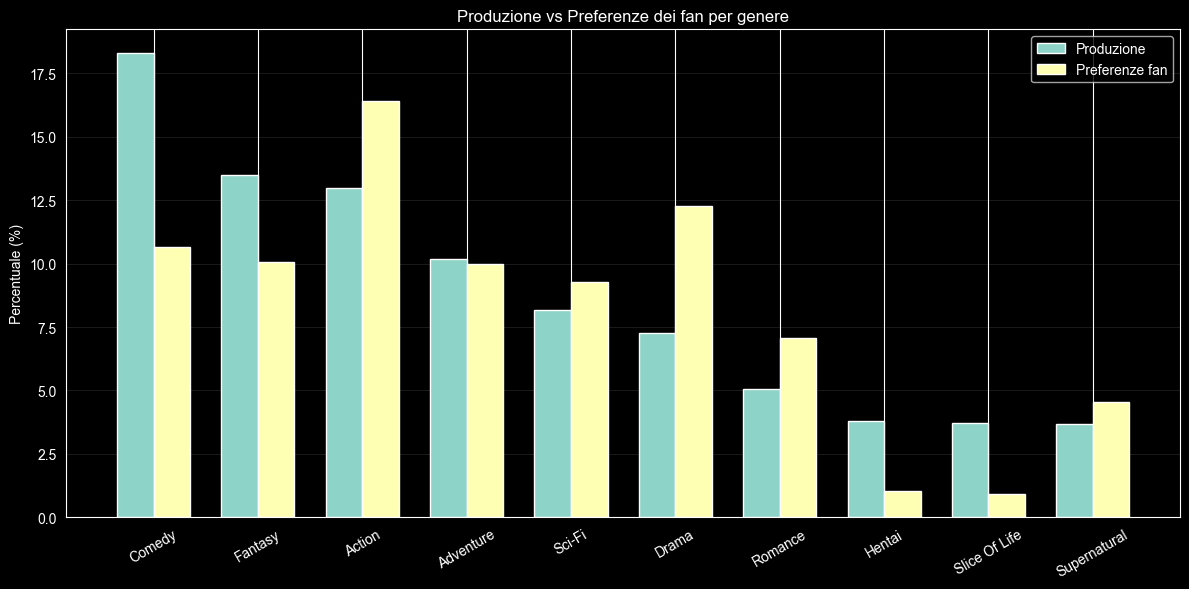

In [9]:
production = genres_df['genres'].value_counts()
production_pct = production / production.sum() * 100

favs_genres = pd.merge(favs, genres_df[['mal_id', 'genres']], on='mal_id', how='inner')
favs_count = favs_genres['genres'].value_counts()
favs_pct = favs_count / favs_count.sum() * 100

compare = pd.DataFrame({'Production (%)': production_pct, 'Fan Preferences (%)': favs_pct}).dropna()
compare = compare.sort_values('Production (%)', ascending=False).head(10)

x = np.arange(len(compare))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width / 2, compare['Production (%)'], width, label='Produzione')
plt.bar(x + width / 2, compare['Fan Preferences (%)'], width, label='Preferenze fan', )
plt.xticks(x, compare.index, rotation=30)
plt.ylabel("Percentuale (%)")
plt.title("Produzione vs Preferenze dei fan per genere")
plt.legend()
plt.grid(axis='y', alpha=0.1)
plt.tight_layout()
plt.show()

Il confronto tra la quota di produzione e le preferenze dei fan evidenzia come le strategie dell’industria anime non siano sempre allineate con i gusti del pubblico.
Mentre generi come Action mostrano un equilibrio tra offerta e domanda, altri come Comedy risultano sovra-rappresentati.
Al contrario, generi come Drama e Romance sembrano essere sottovalutati dall’industria nonostante un forte interesse da parte dei fan.